# CYP Fragment Inhibition Analysis

## Objective

Investigate whether CYP-relevant chemical groups are associated
with differences in measured CYP inhibition potency.

Research questions:
1. Do molecules containing specific chemical groups exhibit
   different pIC50 values?
2. Do these relationships vary across CYP isoforms?
3. Which groups are promising candidates for predictive
   feature evaluation?

This notebook examines associations with inhibition.
It does not establish feature importance or improvement
in machine learning performance.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Our previously extracted binary features
features = pd.read_csv("../data/cyp_features.csv")

# New inhibition measurements
inhibition = pd.read_csv(
    "../data/cyp-challenge-TRAIN_inhibition.csv"
)

print("Feature dataset:", features.shape)
print("Inhibition dataset:", inhibition.shape)

print("\nInhibition columns:")
print(inhibition.columns.tolist())

display(inhibition.head())

Feature dataset: (39505, 13)
Inhibition dataset: (4905, 18)

Inhibition columns:
['Molecule_Name', 'SMILES', 'CYP1A2_pIC50_direct_inhibition', 'CYP2C9_pIC50_direct_inhibition', 'CYP2D6_pIC50_direct_inhibition', 'CYP3A4_pIC50_direct_inhibition', 'CYP1A2_pIC50_direct_inhibition_conf_high', 'CYP2C9_pIC50_direct_inhibition_conf_high', 'CYP2D6_pIC50_direct_inhibition_conf_high', 'CYP3A4_pIC50_direct_inhibition_conf_high', 'CYP1A2_pIC50_direct_inhibition_conf_low', 'CYP2C9_pIC50_direct_inhibition_conf_low', 'CYP2D6_pIC50_direct_inhibition_conf_low', 'CYP3A4_pIC50_direct_inhibition_conf_low', 'CYP1A2_pIC50_direct_inhibition_std', 'CYP2C9_pIC50_direct_inhibition_std', 'CYP2D6_pIC50_direct_inhibition_std', 'CYP3A4_pIC50_direct_inhibition_std']


,Molecule_Name,SMILES,CYP1A2_pIC50_direct_inhibition,CYP2C9_pIC50_direct_inhibition,CYP2D6_pIC50_direct_inhibition,CYP3A4_pIC50_direct_inhibition,CYP1A2_pIC50_direct_inhibition_conf_high,CYP2C9_pIC50_direct_inhibition_conf_high,CYP2D6_pIC50_direct_inhibition_conf_high,CYP3A4_pIC50_direct_inhibition_conf_high,CYP1A2_pIC50_direct_inhibition_conf_low,CYP2C9_pIC50_direct_inhibition_conf_low,CYP2D6_pIC50_direct_inhibition_conf_low,CYP3A4_pIC50_direct_inhibition_conf_low,CYP1A2_pIC50_direct_inhibition_std,CYP2C9_pIC50_direct_inhibition_std,CYP2D6_pIC50_direct_inhibition_std,CYP3A4_pIC50_direct_inhibition_std
0,OCNT-0000422,CC1=C(O)C(C=O)=C(CO)C=N1,NaN,NaN,NaN,2.101240,NaN,NaN,NaN,3.452393,NaN,NaN,NaN,1.048337,NaN,NaN,NaN,0.696258
1,OCNT-0001882,CC(C)(OC1=CC=C(Cl)C=C1)C(=O)O,NaN,2.169687,NaN,NaN,NaN,3.226921,NaN,NaN,NaN,1.069973,NaN,NaN,NaN,0.640165,NaN,NaN
2,OCNT-0007477,CCOC(=O)N1CSCC1C(=O)O,NaN,NaN,NaN,2.577796,NaN,NaN,NaN,3.717840,NaN,NaN,NaN,1.140199,NaN,NaN,NaN,0.720146
3,OCNT-0010068,O=C(O)C1=CN=CC=C1,NaN,NaN,NaN,2.273187,NaN,NaN,NaN,3.566120,NaN,NaN,NaN,1.073916,NaN,NaN,NaN,0.712205
4,OCNT-0014841,NCC1=CC=C(S(N)(=O)=O)C=C1,NaN,NaN,NaN,2.054066,NaN,NaN,NaN,3.429701,NaN,NaN,NaN,1.031887,NaN,NaN,NaN,0.687328


In [4]:
# Keep only molecular and fragment data
features = features.copy()

# Rename the SMILES column for consistency
inhibition = inhibition.rename(
    columns={"SMILES": "smiles"}
)

# Check for duplicate SMILES
print("Duplicate feature SMILES:",
      features["smiles"].duplicated().sum())

print("Duplicate inhibition SMILES:",
      inhibition["smiles"].duplicated().sum())

# Merge the two datasets
merged = features.merge(
    inhibition,
    on="smiles",
    how="inner",
    validate="one_to_one"
)

print("\nMatched molecules:", len(merged))
print("Combined shape:", merged.shape)

display(merged.head())

Duplicate feature SMILES: 0
Duplicate inhibition SMILES: 0

Matched molecules: 4901
Combined shape: (4901, 30)


,smiles,imidazole,"1,2,4-triazole",pyridine,methylenedioxyphenyl,furan / thiophene,steroid core,basic aliphatic amine,carboxylic acid,sulfonamide,...,CYP2D6_pIC50_direct_inhibition_conf_high,CYP3A4_pIC50_direct_inhibition_conf_high,CYP1A2_pIC50_direct_inhibition_conf_low,CYP2C9_pIC50_direct_inhibition_conf_low,CYP2D6_pIC50_direct_inhibition_conf_low,CYP3A4_pIC50_direct_inhibition_conf_low,CYP1A2_pIC50_direct_inhibition_std,CYP2C9_pIC50_direct_inhibition_std,CYP2D6_pIC50_direct_inhibition_std,CYP3A4_pIC50_direct_inhibition_std
0,CC1=CC=C(N(CC2=NCCN2)C2=CC=CC(O)=C2)C=C1,0,0,0,0,0,0,0,0,0,...,5.377572,NaN,NaN,NaN,5.194117,NaN,NaN,NaN,0.045639,NaN
1,C[C@H](CCC(=O)O)[C@H]1CC[C@H]2[C@@H]3CC[C@@H]4...,0,0,0,0,0,1,0,1,0,...,4.869412,NaN,NaN,NaN,4.564008,NaN,NaN,NaN,0.078469,NaN
2,[H][C@@]12CC[C@](O)(C(=O)CO)[C@@]1(C)C[C@H](O)...,0,0,0,0,0,1,0,0,0,...,NaN,3.542516,NaN,NaN,NaN,1.08107,NaN,NaN,NaN,0.711033
3,O=C(O)[C@@H](S)[C@@H](S)C(=O)O,0,0,0,0,0,0,0,1,0,...,4.499312,NaN,NaN,4.044479,4.318086,NaN,NaN,0.300288,0.046690,NaN
4,CC1=CC=C(O)C=C1,0,0,0,0,0,0,0,0,0,...,NaN,NaN,NaN,1.558076,NaN,NaN,NaN,0.566265,NaN,NaN


In [5]:
isoforms = ["CYP1A2", "CYP2C9", "CYP2D6", "CYP3A4"]

target_cols = [
    f"{iso}_pIC50_direct_inhibition"
    for iso in isoforms
]

# Check how many valid measurements exist per isoform
print("Available pIC50 measurements:")
print(merged[target_cols].notna().sum())

# Summary statistics
display(merged[target_cols].describe())

Available pIC50 measurements:
CYP1A2_pIC50_direct_inhibition    1412
CYP2C9_pIC50_direct_inhibition    1285
CYP2D6_pIC50_direct_inhibition    1490
CYP3A4_pIC50_direct_inhibition    2334
dtype: int64


,CYP1A2_pIC50_direct_inhibition,CYP2C9_pIC50_direct_inhibition,CYP2D6_pIC50_direct_inhibition,CYP3A4_pIC50_direct_inhibition
count,1412.000000,1285.000000,1490.000000,2334.000000
mean,4.955410,4.580738,4.781967,4.095745
std,1.030476,0.782295,0.914289,1.093351
min,1.905579,2.097983,1.946780,1.909050
25%,4.557269,4.127431,4.433078,3.395403
50%,5.133334,4.621326,4.724747,4.266182
75%,5.561316,5.049640,5.266014,4.894945
max,7.948525,7.473011,7.534509,7.186666


In [6]:
target = "CYP3A4_pIC50_direct_inhibition"
fragment = "imidazole"

# Keep molecules with valid measurements
subset = merged.dropna(subset=[target])

# Compare fragment presence vs absence
comparison = subset.groupby(fragment)[target].agg(
    ["count", "mean", "median", "std"]
)

display(comparison)

,count,mean,median,std
imidazole,,,,
0,2119,4.072520,4.242173,1.086955
1,215,4.324645,4.506672,1.131830


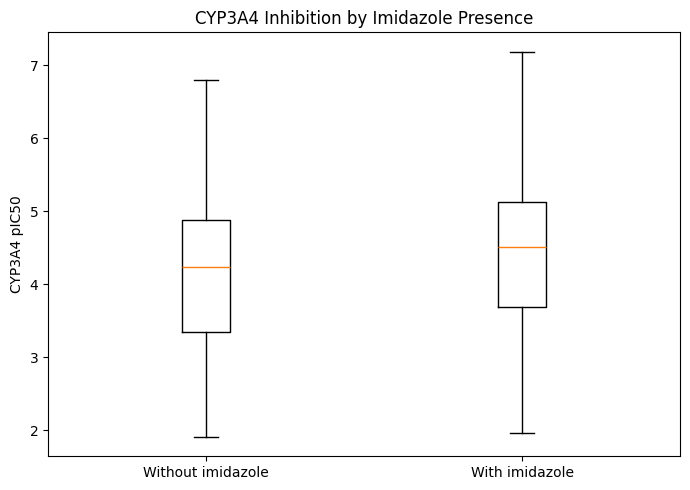

In [7]:
without = subset.loc[
    subset[fragment] == 0, target
]

with_fragment = subset.loc[
    subset[fragment] == 1, target
]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [without, with_fragment],
    tick_labels=["Without imidazole", "With imidazole"]
)

plt.ylabel("CYP3A4 pIC50")
plt.title("CYP3A4 Inhibition by Imidazole Presence")

plt.tight_layout()
plt.show()

In [8]:
# Identify the original fragment columns
feature_cols = features.columns.drop("smiles")

results = []

for isoform in isoforms:

    target = f"{isoform}_pIC50_direct_inhibition"

    subset = merged.dropna(subset=[target])

    for fragment in feature_cols:

        with_group = subset.loc[
            subset[fragment] == 1, target
        ]

        without_group = subset.loc[
            subset[fragment] == 0, target
        ]

        if len(with_group) == 0 or len(without_group) == 0:
            continue

        results.append({
            "Isoform": isoform,
            "Fragment": fragment,
            "N_with": len(with_group),
            "N_without": len(without_group),
            "Mean_with": with_group.mean(),
            "Mean_without": without_group.mean(),
            "Mean_difference": (
                with_group.mean() - without_group.mean()
            )
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Mean_difference",
        ascending=False
    ).round(3)
)

,Isoform,Fragment,N_with,N_without,Mean_with,Mean_without,Mean_difference
11,CYP1A2,nitro,8,1404,5.619,4.952,0.667
39,CYP3A4,methylenedioxyphenyl,25,2309,4.735,4.089,0.647
47,CYP3A4,nitro,7,2327,4.697,4.094,0.603
23,CYP2C9,nitro,2,1283,5.141,4.580,0.561
30,CYP2D6,basic aliphatic amine,554,936,5.128,4.577,0.551
5,CYP1A2,steroid core,1,1411,5.465,4.955,0.510
3,CYP1A2,methylenedioxyphenyl,15,1397,5.402,4.951,0.452
46,CYP3A4,aryl halide,572,1762,4.422,3.990,0.432
35,CYP2D6,nitro,7,1483,5.121,4.780,0.341
24,CYP2D6,imidazole,236,1254,5.063,4.729,0.334


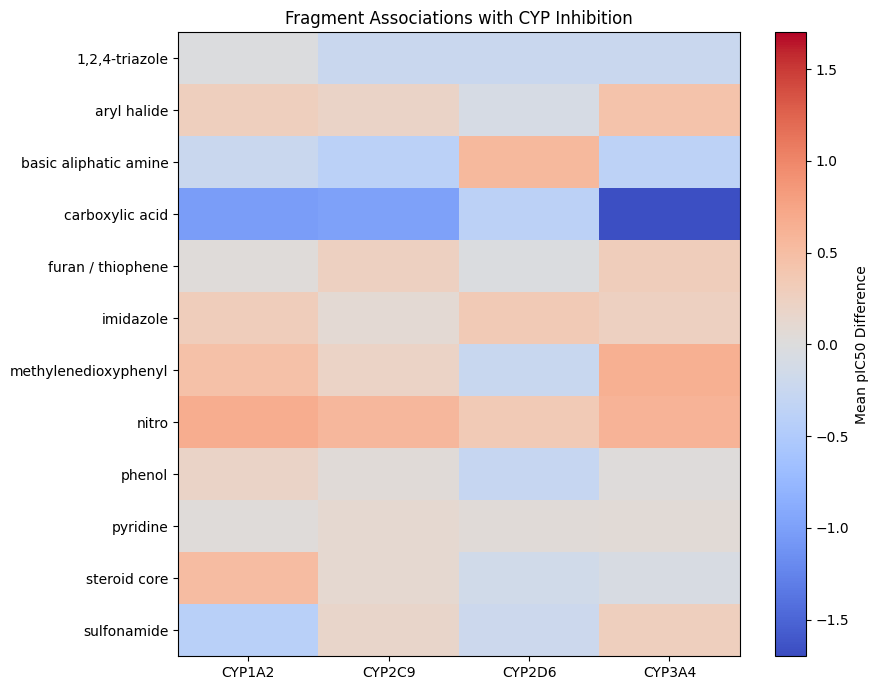

In [9]:
# Create a fragment-by-isoform table
heatmap_data = results_df.pivot(
    index="Fragment",
    columns="Isoform",
    values="Mean_difference"
)

plt.figure(figsize=(9, 7))

plt.imshow(
    heatmap_data,
    cmap="coolwarm",
    aspect="auto",
    vmin=-1.7,
    vmax=1.7
)

plt.colorbar(label="Mean pIC50 Difference")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns
)

plt.yticks(
    range(len(heatmap_data.index)),
    heatmap_data.index
)

plt.title("Fragment Associations with CYP Inhibition")

plt.tight_layout()
plt.show()

## Initial Findings

Analysis of CYP-relevant chemical groups revealed several associations with measured inhibition potency.

Carboxylic acid showed negative mean pIC50 differences across all four CYP isoforms, with the largest observed difference for CYP3A4 (−1.669, n=115). This suggests that carboxylic-acid-containing molecules in the analyzed dataset tend to exhibit lower CYP3A4 inhibition potency.

Basic aliphatic amine showed a notably different pattern across isoforms. It was associated with higher CYP2D6 pIC50 (+0.551, n=554), but lower mean pIC50 for CYP1A2, CYP2C9, and CYP3A4. This suggests that certain fragment features may have isoform-specific relationships with inhibition.

Imidazole and aryl halide also demonstrated positive associations with several CYP isoforms, making them promising candidates for further evaluation.

However, some large observed differences, particularly those involving nitro and methylenedioxyphenyl, were based on relatively few molecules and should be interpreted cautiously.

Overall, these findings identify several candidate features for predictive modeling. Further experiments are needed to determine whether these chemical groups provide additional predictive information beyond standard molecular descriptors and fingerprints.